In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import gc

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import walk_rear

from scamper.agent.task_transfer.walk_rear.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.walk_rear.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.walk_rear.scratch_networks import (
    make_scratch_ppo_networks,
)

In [3]:
CKPT_BASE = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints"

CHECKPOINT_PATHS = [
    # Add your walk_rear checkpoint paths here
    # f"{CKPT_BASE}/YYMMDD_HHMMSS_ffffff",
    f"{CKPT_BASE}/260217_232116_759492",
    f"{CKPT_BASE}/260217_232116_058767",
    f"{CKPT_BASE}/260217_231513_200893",
    f"{CKPT_BASE}/260217_222123_239916",
    f"{CKPT_BASE}/260217_222112_031771",
    f"{CKPT_BASE}/260217_222111_084405",
]

EPISODE_LENGTH = 500  # Rollout steps (matches walk_rear config)
SEED = 0  # Single rollout seed per model

In [4]:
def load_model(checkpoint_path, checkpoint_step=None):
    """Load a trained walk_rear model and return everything needed for rollouts.

    Returns:
        (jit_reset, jit_step, jit_inference_fn, brax_params, target_pos,
         skull_body_id, config)
    """
    # Load metadata
    ckpt_info = load_task_transfer_metadata(checkpoint_path, step=checkpoint_step)
    config = ckpt_info["config"]
    ckpt_step = ckpt_info["step"]
    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    target_pos = np.array([
        config["env"]["target_x"],
        config["env"]["target_y"],
        config["env"]["target_z"],
    ])
    print(f"Loading checkpoint: {checkpoint_path}")
    print(f"  Mode: {mode}, Step: {ckpt_step}, Target: {target_pos}")

    # Load frozen networks from prior checkpoint
    prior_checkpoint_path = config["checkpoint"]["path"]
    prior_checkpoint_step = config["checkpoint"]["step"]

    (
        encoder_params,
        prior_params,
        decoder_params,
        normalizer_params,
        _,
    ) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
    action_size = ckpt_cfg["network_config"]["action_size"]

    # Create environment
    env_cfg = walk_rear.default_config()

    xml_variant = config["env"].get("xml_variant", "full-collisions")
    if xml_variant == "limited-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
    elif xml_variant == "full-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
    elif xml_variant == "no-tail-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
    else:
        raise ValueError(f"Unknown xml_variant: {xml_variant}")

    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.target_x = config["env"]["target_x"]
    env_cfg.target_y = config["env"]["target_y"]
    env_cfg.target_z = config["env"]["target_z"]
    env_cfg.xy_tolerance = config["env"]["xy_tolerance"]
    env_cfg.z_tolerance = config["env"]["z_tolerance"]
    env_cfg.hold_duration = config["env"]["hold_duration"]
    env_cfg.distance_margin = config["env"]["distance_margin"]
    env_cfg.reward_terms = {
        "distance_to_target": {"weight": config["env"]["reward_weights"]["distance_to_target"]},
        "walk_rear_success": {"weight": config["env"]["reward_weights"]["walk_rear_success"]},
    }
    env_cfg.torque_actuators = True

    # Set actuator type for scratch mode
    if mode == "scratch":
        env_cfg.torque_actuators = config["scratch"].get("torque_actuators", True)

    # Create decoder inference function and wrap environment
    decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
    base_env = walk_rear.WalkRear(config=env_cfg)

    # Get skull body index for distance computation
    skull_body_id = base_env._mj_model.body("skull-rodent").id

    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    elif mode == "prior_decoder":
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=config["prior_decoder"]["deterministic_prior"],
            noise_logvar=config["prior_decoder"]["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    # JIT-compile reset and step
    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    # Build network and load parameters
    rng = jax.random.PRNGKey(0)
    start_state = jit_reset(rng)
    obs_size = start_state.obs.shape[-1]
    normalize = running_statistics.normalize
    policy_action_size = env.action_size

    if mode == "scratch":
        task_obs_size = obs_size - proprio_size
        decoder_hidden_layer_sizes = tuple(
            ckpt_cfg["network_config"]["decoder_layer_sizes"]
        )

        def network_factory(*args, **kwargs):
            return make_scratch_ppo_networks(
                task_obs_size=task_obs_size,
                proprio_size=proprio_size,
                action_size=action_size,
                latent_size=latent_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        checkpoint_path, abstract_brax_params, step=ckpt_step
    )

    # Create deterministic inference function
    if mode == "scratch":
        ppo_network = network_factory()
    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

    jit_inference_fn = jax.jit(inference_fn)

    print(f"  Model loaded successfully.")
    return jit_reset, jit_step, jit_inference_fn, brax_params, target_pos, skull_body_id, config

In [5]:
def run_rollout(jit_reset, jit_step, jit_inference_fn, brax_params, target_pos,
                skull_body_id, seed, episode_length):
    """Run a single rollout and return per-step skull-to-target distance.

    Returns:
        dict with:
            'distances': np.ndarray of shape (episode_length,) — 3D skull-to-target distance
            'success': bool — whether the hold condition was met
            'time_to_success': int — timestep of success (0 if no success)
    """
    rng = jax.random.PRNGKey(seed)
    reset_rng, act_rng = jax.random.split(rng)

    state = jit_reset(reset_rng)
    distances = []
    success = False
    time_to_success = 0

    for t in range(episode_length):
        _, act_rng = jax.random.split(act_rng)
        action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
        state = jit_step(state, action)

        # Compute skull-to-target distance
        skull_pos = np.array(state.data.xpos[skull_body_id])
        dist = np.linalg.norm(skull_pos - target_pos)
        distances.append(dist)

        # Check success from metrics
        if not success and float(state.metrics.get("success", 0.0)) > 0.5:
            success = True
            time_to_success = t + 1

    return {
        "distances": np.array(distances),
        "success": success,
        "time_to_success": time_to_success,
    }

In [6]:
# Run one rollout per model, clearing memory after each
from collections import defaultdict

raw_results = []  # List of (mode, rollout_dict)

for i, ckpt_path in enumerate(CHECKPOINT_PATHS):
    print(f"[{i + 1}/{len(CHECKPOINT_PATHS)}]")
    jit_reset, jit_step, jit_inference_fn, brax_params, target_pos, skull_body_id, config = (
        load_model(ckpt_path)
    )
    mode = config["mode"]

    result = run_rollout(
        jit_reset, jit_step, jit_inference_fn, brax_params, target_pos,
        skull_body_id, SEED, EPISODE_LENGTH
    )
    raw_results.append((mode, result))
    print(
        f"  Mode: {mode}, Final dist: {result['distances'][-1]:.3f} m, "
        f"Success: {result['success']}, Time: {result['time_to_success']}"
    )

    # Free model objects and clear caches to avoid OOM
    del jit_reset, jit_step, jit_inference_fn, brax_params, config
    jax.clear_caches()
    gc.collect()
    print()

# Group by mode
grouped = defaultdict(list)
for mode, result in raw_results:
    grouped[mode].append(result)

print("Summary:")
for mode in sorted(grouped):
    results = grouped[mode]
    n = len(results)
    n_success = sum(r["success"] for r in results)
    final_dists = [r["distances"][-1] for r in results]
    print(
        f"  {mode}: n={n}, success={n_success}/{n}, "
        f"final dist = {np.mean(final_dists):.3f} +/- {np.std(final_dists):.3f} m"
    )

[1/6]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260217_232116_759492
  Mode: prior_decoder, Step: 90, Target: [0.5 0.  0.2]
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 9.80 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 1.71 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 1.79 ms  (cached)
Module _primitive_narrowphase__locals__p

In [8]:
# Save rollout results for reuse without re-running rollouts
import pandas as pd
from pathlib import Path

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/walk_rear_analysis")
save_dir.mkdir(parents=True, exist_ok=True)

# Save as long-format CSV: rollout_idx, mode, timestep, distance, success, time_to_success
rows = []
for rollout_idx, (mode, result) in enumerate(raw_results):
    for t, d in enumerate(result["distances"]):
        rows.append({
            "rollout_idx": rollout_idx,
            "mode": mode,
            "timestep": t,
            "distance": d,
            "success": result["success"],
            "time_to_success": result["time_to_success"],
        })

df_results = pd.DataFrame(rows)
csv_path = save_dir / "walk_rear_distance_rollouts.csv"
df_results.to_csv(csv_path, index=False)
print(f"Saved {len(df_results)} rows ({len(raw_results)} rollouts) to {csv_path}")
df_results.head()

Saved 3000 rows (6 rollouts) to /home/mila/a/aidan.sirbu/SCAMPER/data/walk_rear_analysis/walk_rear_distance_rollouts.csv


,rollout_idx,mode,timestep,distance,success,time_to_success
0,0,prior_decoder,0,0.433992,True,176
1,0,prior_decoder,1,0.433924,True,176
2,0,prior_decoder,2,0.433732,True,176
3,0,prior_decoder,3,0.433317,True,176
4,0,prior_decoder,4,0.431892,True,176


In [9]:
# Load rollout results from CSV (skip cells 0-5 if data already saved)
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict

csv_path = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/walk_rear_analysis/walk_rear_distance_rollouts.csv")
df_loaded = pd.read_csv(csv_path)

# Reconstruct grouped dict: mode -> list of result dicts
grouped = defaultdict(list)
for rollout_idx in df_loaded["rollout_idx"].unique():
    rollout_df = df_loaded[df_loaded["rollout_idx"] == rollout_idx].sort_values("timestep")
    mode = rollout_df["mode"].iloc[0]
    grouped[mode].append({
        "distances": rollout_df["distance"].values,
        "success": rollout_df["success"].iloc[0],
        "time_to_success": int(rollout_df["time_to_success"].iloc[0]),
    })

print(f"Loaded {len(df_loaded['rollout_idx'].unique())} rollouts from {csv_path}")
print(f"Modes: {sorted(grouped.keys())}")
for mode in sorted(grouped):
    results = grouped[mode]
    n_success = sum(r["success"] for r in results)
    print(f"  {mode}: n={len(results)}, success={n_success}/{len(results)}")

Loaded 6 rollouts from /home/mila/a/aidan.sirbu/SCAMPER/data/walk_rear_analysis/walk_rear_distance_rollouts.csv
Modes: ['decoder_only', 'prior_decoder']
  decoder_only: n=3, success=3/3
  prior_decoder: n=3, success=2/3


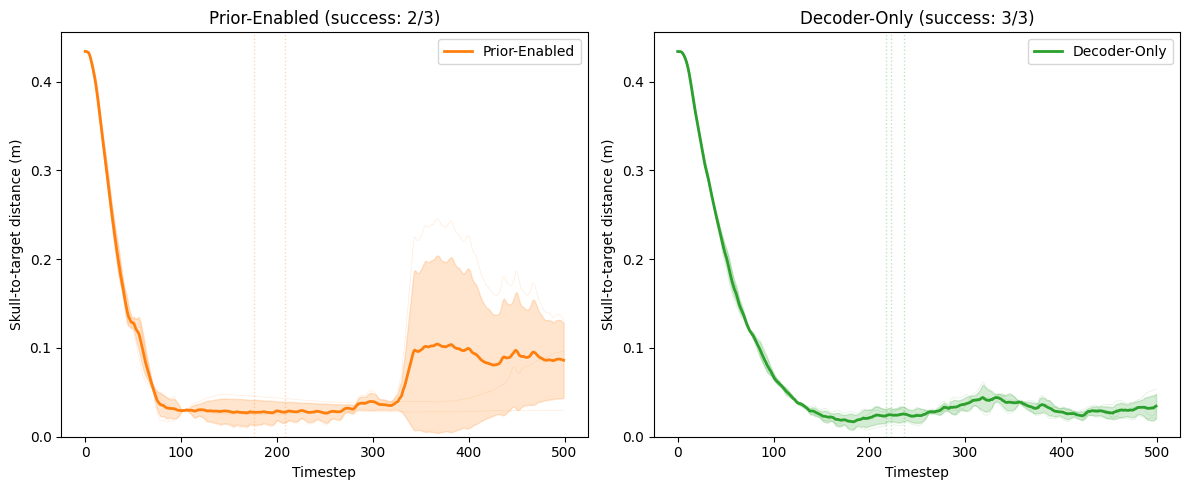

In [10]:
# Plot skull-to-target distance over time, one subplot per training mode
import matplotlib.pyplot as plt

MODE_LABELS = {
    "scratch": "Scratch",
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
}
MODE_COLORS = {
    "scratch": "tab:blue",
    "prior_decoder": "tab:orange",
    "decoder_only": "tab:green",
}
MODE_ORDER = ["scratch", "prior_decoder", "decoder_only"]

# Only plot modes that have data
modes_with_data = [m for m in MODE_ORDER if m in grouped]

fig, axes = plt.subplots(1, len(modes_with_data), figsize=(6 * len(modes_with_data), 5))
if len(modes_with_data) == 1:
    axes = [axes]

for ax, mode in zip(axes, modes_with_data):
    results = grouped[mode]
    all_dists = np.array([r["distances"] for r in results])  # (n_rollouts, episode_length)
    timesteps = np.arange(all_dists.shape[1])
    mean_dist = np.mean(all_dists, axis=0)
    std_dist = np.std(all_dists, axis=0)
    color = MODE_COLORS[mode]

    # Individual rollouts (thin lines)
    for r in results:
        ax.plot(timesteps, r["distances"], color=color, alpha=0.15, linewidth=0.5)

    # Mean +/- std
    ax.plot(timesteps, mean_dist, color=color, linewidth=2, label=MODE_LABELS[mode])
    ax.fill_between(timesteps, mean_dist - std_dist, mean_dist + std_dist, alpha=0.2, color=color)

    # Mark success times
    for r in results:
        if r["success"]:
            t = r["time_to_success"]
            ax.axvline(t, color=color, linestyle=":", alpha=0.3, linewidth=1)

    n_success = sum(r["success"] for r in results)
    ax.set_xlabel("Timestep")
    ax.set_ylabel("Skull-to-target distance (m)")
    ax.set_title(f"{MODE_LABELS[mode]} (success: {n_success}/{len(results)})")
    ax.legend(loc="upper right")
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

Prior-Enabled: success 2/3
Decoder-Only: success 3/3
Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/walk_rear_distance.[pdf|svg|png]


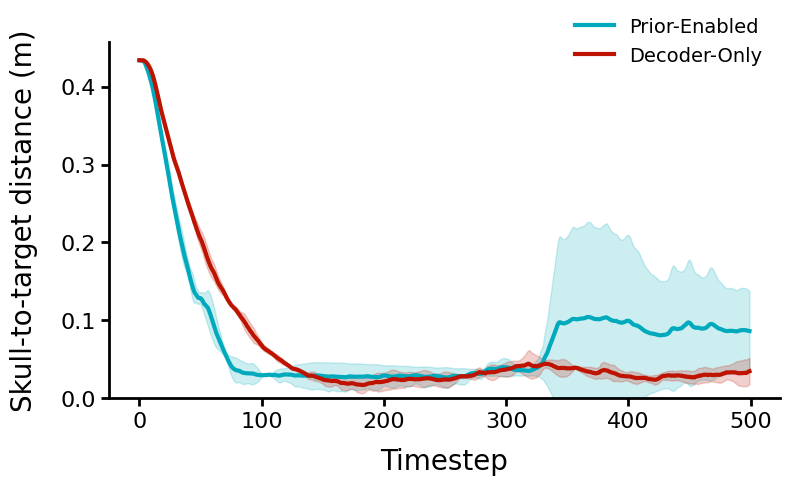

In [11]:
# Combined plot: all modes on one axis
import seaborn as sns

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "walk_rear_distance"

# Build long-format DataFrame for seaborn
plot_rows = []
for mode in modes_with_data:
    for r in grouped[mode]:
        for t, d in enumerate(r["distances"]):
            plot_rows.append({
                "Timestep": t,
                "Skull-to-target distance (m)": d,
                "Training Mode": MODE_LABELS[mode],
            })

df_plot = pd.DataFrame(plot_rows)

palette = {
    "Prior-Enabled": tuple(c / 255 for c in (0, 170, 188)),
    "Decoder-Only": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}
hue_order = [MODE_LABELS[m] for m in modes_with_data]

fig, ax = plt.subplots(figsize=(8, 5))

sns.lineplot(
    data=df_plot,
    x="Timestep",
    y="Skull-to-target distance (m)",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    linewidth=3,
    ax=ax,
)

ax.set_xlabel("Timestep", fontsize=20, labelpad=12)
ax.set_ylabel("Skull-to-target distance (m)", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.set_ylim(bottom=0)

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# Add success rate annotation
for mode in modes_with_data:
    results = grouped[mode]
    n_success = sum(r["success"] for r in results)
    print(f"{MODE_LABELS[mode]}: success {n_success}/{len(results)}")

ax.legend(fontsize=14, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.12))

plt.tight_layout()

fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()